In [52]:
# SETUP - run this cell once, then any cell below on its own #################
#
# Every other cell needs this one and nothing else. Packages, paths and the
# build steps all live here, so after reopening the notebook you run this and
# then whichever cell you actually want.
#
# The build steps are functions rather than inline code because each one is
# needed by more than one cell downstream. They re-read from disk each call
# (a few seconds), which is what buys the independence.
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from tqdm import tqdm

PLOT_OUTPUT = (
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/"
)

# ---- FHS indicators -------------------------------------------------------
FHS_ROOT = "/mnt/share/forecasting/data/32/future/death/future_death_aggregated_rate_s130v156_q0_indicators/"
U5M_PATH = os.path.join(FHS_ROOT, "u5mr_5q0.csv")
NMR_PATH = os.path.join(FHS_ROOT, "nmr_28dayq0.csv")
# FHS publishes deaths per 1000 livebirths; the pipeline works in probability
FHS_RATE_PER = 1000.0

# ---- RRA neonatal results -------------------------------------------------
NMR_RRA_ROOT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_10_08.01/"
# Shifted draws: model + residual + GBD anchor. These are the pipeline's
# published output and what table1_cumulative_case_counts.csv is built from,
# so the scenario effect taken from them matches what the pipeline reports.
NMR_RRA_REF_PATH = os.path.join(NMR_RRA_ROOT, "ssp245_shifted.parquet")
NMR_RRA_BETTER_PATH = os.path.join(NMR_RRA_ROOT, "ssp126_shifted.parquet")
NMR_RRA_WORSE_PATH = os.path.join(NMR_RRA_ROOT, "ssp585_shifted.parquet")

# Unshifted (raw model) draws. Not used: see the scenario cell. Kept because
# they are the obvious alternative and the reason against them is specific.
NMR_RRA_REF_RAW_PATH = os.path.join(NMR_RRA_ROOT, "ssp245.parquet")
NMR_RRA_BETTER_RAW_PATH = os.path.join(NMR_RRA_ROOT, "ssp126.parquet")
NMR_RRA_WORSE_RAW_PATH = os.path.join(NMR_RRA_ROOT, "ssp585.parquet")

# ---- shared inputs for aggregation ---------------------------------------
PLOT_OUTPUT = (
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/"
)
NEONATAL_PLOT_FILE = "neonatal_superregion_scenarios.png"
NEONATAL_YLABEL = "Neonatal deaths per 1000 livebirths"
U5M_YLABEL = "Under-5 deaths per 1000 livebirths"
NEONATAL_TABLE_FILE = "neonatal_cumulative_scenario_differences.csv"

# The pipeline's own forecast population, copied from
# rra_climate_health/inference/run_inference.py:44 in the _2 clone (the one
# that produced results 2026_10_08.01). Not imported, because this kernel
# resolves rra_climate_health to the other clone, which pins a different
# file (release 9) and would silently change the counts.
# NOTE: this is population, not live births. The pipeline has no live births
# source anywhere; neonatal mortality is weighted by the age 42 population
# stock (ages 2 + 3).
FHS_POP_PATH = "/mnt/share/forecasting/data/32/future/population/future_population_s130v41/population.nc"
FHS_HIERARCHY_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/fhs_hierarchy.parquet"
# the population file has no age_group_id 42; neonatal is early + late
# neonatal, which is what constants.AGE_GROUP_AGGREGATES says 42 is made of
NEONATAL_POP_PARTS = [2, 3]

# ---- keys, labels and analysis settings ----------------------------------
SCEN_KEYS = ["age_group_id", "sex_id", "location_id", "year_id"]
NEONATAL_AGE_GROUP_ID = 42
BOTH_SEXES_ID = 3  # FHS publishes a Both row; RRA models sexes 1 and 2
SCENARIO_LABELS = {"reference": "ssp245", "better": "ssp126", "worse": "ssp585"}
REFERENCE_SSP, BETTER_SSP, WORSE_SSP = "ssp245", "ssp126", "ssp585"
SCENARIO_ORDER = ["ssp126", "ssp245", "ssp585"]
SCENARIO_COLOURS = ["#2a78d6", "#52514e", "#eb6834"]
# shown on the figure; the SSP names stay in the data
SCENARIO_DISPLAY = {"ssp126": "RCP 2.6", "ssp245": "RCP 4.5", "ssp585": "RCP 8.5"}
SCENARIO_LEGEND_TITLE = "Representative Control Pathways (RCP) Scenarios"
SCENARIO_PAIRS = [("ssp585", "ssp126"), ("ssp585", "ssp245"), ("ssp245", "ssp126")]
FIRST_FORECAST_YEAR = 2024
ANALYSIS_YEARS = [2050, 2100]
# one draw column: there is no uncertainty to carry, so the point estimate is
# written straight in. Consumers average across draws, which returns it
# unchanged, and the name stays a subset of the population file's draw_0..249.
DRAW_COLS = ["draw_0"]

# filled in by build_nmr_fhs_scenarios(): how many values the zero floor touched
nmr_fhs_clipped: dict[str, int] = {}


def _draw_mean(path, name):
    """Mean over the draw columns of an RRA results file, keyed for a merge."""
    d = pd.read_parquet(path).mean(axis=1).rename(name).reset_index()
    return d.drop(columns=[c for c in ("scenario",) if c in d.columns])


def load_neonatal_population():
    """Age 42 population (ages 2 + 3), the pipeline's weight for this measure."""
    return (
        xr.open_dataset(FHS_POP_PATH)["draws"]
        .sel(age_group_id=NEONATAL_POP_PARTS)
        .sum("age_group_id")
        .mean("draw")
        .squeeze(drop=True)
        .to_dataframe(name="population")
        .reset_index()[["location_id", "year_id", "sex_id", "population"]]
    )


def rra_absolute_differences():
    """Scenario minus reference, in absolute prevalence, at RRA's own locations.

    Taken from the SHIFTED files, which are the pipeline's published output
    and what table1_cumulative_case_counts.csv is built from.
    """
    d = (
        _draw_mean(NMR_RRA_REF_PATH, "ref")
        .merge(_draw_mean(NMR_RRA_BETTER_PATH, "better"), on=SCEN_KEYS)
        .merge(_draw_mean(NMR_RRA_WORSE_PATH, "worse"), on=SCEN_KEYS)
    )
    d["abs_better"] = d["better"] - d["ref"]
    d["abs_worse"] = d["worse"] - d["ref"]
    return d


def aggregate_rra_deltas():
    """Neonatal scenario deltas, aggregated to every location."""
    return aggregate_deltas(
        rra_absolute_differences(), load_neonatal_population(), NEONATAL_AGE_GROUP_ID
    )


def build_nmr_fhs_scenarios():
    """FHS neonatal series with the RRA scenario deltas added."""
    return apply_deltas_to_fhs(NMR_PATH, aggregate_rra_deltas())


def build_nmr_fhs_counts():
    """Neonatal deaths and population weight, globe and super regions."""
    return counts_from_scenarios(build_nmr_fhs_scenarios())


def build_nmr_fhs_shifted_prevalence():
    """The scenario series in the pipeline's shifted_prevalence shape.

    Filtered to the most-detailed locations and sexes 1/2, because that is
    what the pipeline's own file holds. build_nmr_fhs_scenarios now also
    carries the aggregate levels and the Both-sex rows, which belong in the
    plots and the table but not in a file meant to be aggregated downstream -
    including them would double count.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    detailed = set(hier.loc[hier["most_detailed"] == 1, "location_id"])
    f = build_nmr_fhs_scenarios()
    f = f[f["location_id"].isin(detailed) & (f["sex_id"] != BOTH_SEXES_ID)].copy()
    f["scenario"] = f["scenario"].map(SCENARIO_LABELS)
    if f["scenario"].isna().any():
        msg = "unmapped scenario label"
        raise ValueError(msg)
    return pd.DataFrame(
        np.repeat((f["mean"].to_numpy() / FHS_RATE_PER)[:, None], len(DRAW_COLS), 1),
        columns=DRAW_COLS,
        index=pd.MultiIndex.from_frame(
            f[["location_id", "year_id", "sex_id", "age_group_id", "scenario"]]
        ),
    ).sort_index()


# ---- child mortality (5q0) ------------------------------------------------
# RRA has no directly usable 5q0. The direct run (2026_10_01.01) is properly
# anchored but falls below 28q0 in 216 locations after 2023, which is
# impossible - neonatal deaths are a subset of under-5 deaths. 5q28 was
# modelled separately to fix that, so 5q0 is rebuilt from the two parts.
CM_RRA_ROOT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/results/2026_10_16.01/"
NMR_RRA_SHIFTED = {
    s: os.path.join(NMR_RRA_ROOT, f"{s}_shifted.parquet") for s in SCENARIO_ORDER
}
CM_RRA_SHIFTED = {
    s: os.path.join(CM_RRA_ROOT, f"{s}_shifted.parquet") for s in SCENARIO_ORDER
}
UNDER5_AGE_GROUP_ID = 1
# what AGE_GROUP_AGGREGATES[1] expands to in the pipeline
UNDER5_POP_PARTS = [2, 3, 388, 389, 238, 34]
U5M_PLOT_FILE = "child_mortality_superregion_scenarios.png"
U5M_TABLE_FILE = "child_mortality_cumulative_scenario_differences.csv"

DRAW_IDX = ["location_id", "year_id", "sex_id"]


def load_under5_population():
    """Age 1 population (ages 2, 3, 388, 389, 238, 34), the pipeline's weight."""
    return (
        xr.open_dataset(FHS_POP_PATH)["draws"]
        .sel(age_group_id=UNDER5_POP_PARTS)
        .sum("age_group_id")
        .mean("draw")
        .squeeze(drop=True)
        .to_dataframe(name="population")
        .reset_index()[["location_id", "year_id", "sex_id", "population"]]
    )


def rra_5q0_draws(scenario):
    """5q0 = 1 - (1 - 28q0) * (1 - 5q28), draw by draw, for one scenario.

    Draw by draw and not on the draw means, because the identity is not
    linear. Both parents are the shifted (post-residual) files.
    """

    def _load(path):
        d = pd.read_parquet(path).reset_index()
        return d.drop(columns=["age_group_id", "scenario"]).set_index(DRAW_IDX)

    neo = _load(NMR_RRA_SHIFTED[scenario])
    cm = _load(CM_RRA_SHIFTED[scenario]).reindex(neo.index)
    if cm.isna().any().any():
        msg = "28q0 and 5q28 do not cover the same location/year/sex rows"
        raise ValueError(msg)
    return 1.0 - (1.0 - neo) * (1.0 - cm)


def rra_5q0_absolute_differences():
    """Scenario minus reference for the recombined 5q0, in absolute terms."""
    draws = {s: rra_5q0_draws(s).mean(axis=1) for s in SCENARIO_ORDER}
    d = pd.DataFrame(
        {
            "ref": draws[REFERENCE_SSP],
            "better": draws[BETTER_SSP],
            "worse": draws[WORSE_SSP],
        }
    ).reset_index()
    d["abs_better"] = d["better"] - d["ref"]
    d["abs_worse"] = d["worse"] - d["ref"]
    d["age_group_id"] = UNDER5_AGE_GROUP_ID
    return d


def aggregate_deltas(deltas, population, age_group_id):
    """Roll scenario deltas up the hierarchy the way the pipeline does.

    Explode `path_to_top_parent` so each most-detailed location lands in every
    ancestor, then take the population-weighted mean - the same arithmetic as
    aggregate_forecast_hierarchy(counts=False). sex_id 3 is added as the
    both-sex aggregate so FHS's "Both" rows can be matched. The summed
    population travels with it, since the counts step needs the same weight.

    This is the ONLY thing aggregated anywhere in this notebook. FHS already
    publishes every level correctly; re-deriving its aggregates would only
    replace them with worse ones.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    d = deltas.merge(population, on=DRAW_IDX, how="inner")
    anc = hier.loc[
        hier["most_detailed"] == 1, ["location_id", "path_to_top_parent"]
    ].copy()
    anc["agg_id"] = anc["path_to_top_parent"].str.split(",")
    anc = anc.explode("agg_id")
    anc["agg_id"] = anc["agg_id"].astype(int)
    d = d.merge(anc[["location_id", "agg_id"]], on="location_id")

    for col in ("abs_better", "abs_worse"):
        d[f"_w_{col}"] = d[col] * d["population"]

    def _collapse(frame, keys):
        out = frame.groupby(keys, as_index=False)[
            ["_w_abs_better", "_w_abs_worse", "population"]
        ].sum()
        for col in ("abs_better", "abs_worse"):
            out[col] = out[f"_w_{col}"] / out["population"]
        return out.drop(columns=["_w_abs_better", "_w_abs_worse"])

    by_sex = _collapse(d, ["agg_id", "year_id", "sex_id"])
    both = _collapse(d, ["agg_id", "year_id"])
    both["sex_id"] = BOTH_SEXES_ID
    out = pd.concat([by_sex, both], ignore_index=True)
    out["age_group_id"] = age_group_id
    return out.rename(columns={"agg_id": "location_id"})


def apply_deltas_to_fhs(fhs_path, deltas):
    """FHS series as published, plus the aggregated RRA delta.

        out = fhs_published + (scenario - reference) * 1000

    so the gap between scenarios is RRA's and the levels are FHS's. Nothing
    rescales it; the only thing that can change the gap is the floor at zero.
    """
    fhs = pd.read_csv(fhs_path)
    wide = fhs.merge(
        deltas[SCEN_KEYS + ["abs_better", "abs_worse", "population"]],
        on=SCEN_KEYS,
        how="inner",
    )
    nmr_fhs_clipped.clear()
    for lab in ("better", "worse"):
        v = wide["mean"] + wide[f"abs_{lab}"] * FHS_RATE_PER
        nmr_fhs_clipped[f"mean_{lab}"] = int((v < 0).sum())
        wide[f"mean_{lab}"] = v.clip(lower=0.0)

    keep = list(fhs.columns.drop(["upper", "lower"])) + ["population"]
    base = wide[keep]
    parts = [base.assign(scenario="reference")]
    for lab in ("better", "worse"):
        p = base.copy()
        p["scenario"] = lab
        p["mean"] = wide[f"mean_{lab}"].to_numpy()
        parts.append(p)
    return pd.concat(parts, ignore_index=True)


def counts_from_scenarios(scen):
    """Deaths and the population weight, globe and super regions, Both sexes."""
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    table_locs = set(hier.loc[hier["level"] < 2, "location_id"])
    out = scen[
        scen["location_id"].isin(table_locs) & (scen["sex_id"] == BOTH_SEXES_ID)
    ].copy()
    out["count"] = out["mean"] / FHS_RATE_PER * out["population"]
    out["rate"] = out["mean"]
    out["scenario"] = out["scenario"].map(SCENARIO_LABELS)
    return out[
        ["location_id", "scenario", "year_id", "count", "population", "rate"]
    ].reset_index(drop=True)


def build_u5m_fhs_scenarios():
    """FHS under-5 series with the recombined RRA 5q0 scenario deltas added."""
    deltas = aggregate_deltas(
        rra_5q0_absolute_differences(), load_under5_population(), UNDER5_AGE_GROUP_ID
    )
    return apply_deltas_to_fhs(U5M_PATH, deltas)


def build_u5m_fhs_counts():
    """Under-5 deaths and population weight, globe and super regions."""
    return counts_from_scenarios(build_u5m_fhs_scenarios())


def cumulative_difference_table(counts):
    """Cumulative scenario difference in deaths, millions, at ANALYSIS_YEARS."""
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    cum = counts.query("year_id >= @FIRST_FORECAST_YEAR").sort_values("year_id").copy()
    cum["cum_count"] = cum.groupby(["location_id", "scenario"])["count"].cumsum()
    wide = cum.pivot_table(
        index=["location_id", "year_id"], columns="scenario", values="cum_count"
    )
    rows = []
    for a, b in SCENARIO_PAIRS:
        d = (wide[a] - wide[b]).rename("diff").reset_index()
        d["scenario"] = f"{a} - {b}"
        rows.append(d)
    table = (
        pd.concat(rows)
        .query("year_id in @ANALYSIS_YEARS")
        .merge(
            hier[["location_id", "location_name", "sort_order"]],
            on="location_id",
            how="left",
        )
        .sort_values(["year_id", "sort_order", "scenario"])
    )
    # six decimals, so millions x 1e6 lands back on whole deaths
    table["millions"] = (table["diff"] / 1e6).round(6)
    return table[["year_id", "location_name", "scenario", "millions"]].reset_index(
        drop=True
    )


def plot_superregion_rates(counts, ylabel=NEONATAL_YLABEL, ncol=4):
    """Neonatal rate by scenario, one panel per globe/super region.

    Four panels across, so the globe and the seven super regions fill two
    rows exactly. One legend for the whole figure, below the panels, rather
    than a per-axes one competing with the curves. The y axis is shared, so
    panel heights are comparable at a glance - at the cost of flattening the
    low-mortality regions, which span 1.3-2.8 against Sub-Saharan Africa's
    7-23 per 1000.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    locs = (
        hier[hier["location_id"].isin(counts.location_id.unique())]
        .query("level < 2")
        .sort_values("sort_order")
    )
    nrow = int(np.ceil(len(locs) / ncol))
    fig, axes = plt.subplots(
        nrow, ncol, figsize=(4.0 * ncol, 3.4 * nrow), sharex=True, sharey=True
    )
    handles = []
    for ax, (_, loc) in zip(axes.flatten(), locs.iterrows()):
        panel = counts[counts["location_id"] == loc["location_id"]]
        for scen, colour in zip(SCENARIO_ORDER, SCENARIO_COLOURS):
            s = panel[panel["scenario"] == scen].sort_values("year_id")
            (line,) = ax.plot(s["year_id"], s["rate"], color=colour, lw=2)
            if len(handles) < len(SCENARIO_ORDER):
                line.set_label(SCENARIO_DISPLAY[scen])
                handles.append(line)
        ax.set_title(loc["location_name"], fontsize=12)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.tick_params(labelsize=10)
    for ax in axes.flatten()[len(locs) :]:
        ax.set_visible(False)
    fig.supylabel(ylabel, fontsize=12)
    fig.tight_layout(rect=[0, 0.08, 1, 1])
    fig.legend(
        handles=handles,
        title=SCENARIO_LEGEND_TITLE,
        loc="lower center",
        ncol=len(SCENARIO_ORDER),
        frameon=False,
        fontsize=11,
        title_fontsize=12,
        bbox_to_anchor=(0.5, 0.0),
    )
    return fig

In [ ]:
u5m_fhs_df = pd.read_csv(U5M_PATH)
nmr_fhs_df = pd.read_csv(NMR_PATH)
nmr_fhs_df.head()

### NEONATAL

In [ ]:
nmr_rra_worse_df = pd.read_parquet(NMR_RRA_WORSE_PATH).reset_index()
nmr_rra_better_df = pd.read_parquet(NMR_RRA_BETTER_PATH).reset_index()

In [ ]:
# Apply RRA scenario differences to the FHS neonatal series ##################
#
# Same move as goal_keepers/.../ad_hoc/stunting_apply_genem_difs.py with the
# two roles swapped: there GENEM supplies the scenario spread and the Rapid
# Response series is modified, here RRA supplies the spread and FHS is
# modified. The spread is carried across as a RELATIVE difference,
#
#     rel = (scenario - reference) / reference
#     out = fhs_reference * (1 + rel)
#
# which is what lets the two be combined at all: RRA draws are probabilities
# on 0-1 while the FHS indicator is deaths per 1000 livebirths, so an absolute
# difference would be meaningless across that gap and a ratio is not.
#
# ssp245 is the reference, ssp126 the better scenario (less warming, lower
# mortality, so rel is negative) and ssp585 the worse. Only the central
# estimate is carried through; the FHS upper/lower are dropped rather than
# scaled, since a scaled interval would look like a modelled one.
#
# Why the UNSHIFTED scenario files
# --------------------------------
# `ssp*.parquet` are the raw model draws; `ssp*_shifted.parquet` are those
# plus the residual model and the GBD anchor. The shifted files look like the
# natural choice and are the wrong one, because of a single line in
# run_residual.py: each scenario's draws are clipped with
# `shifted_scenario.clip(lower=0.0)`. The residual model is an additive
# extrapolation in prevalence space with nothing bounding it, so far from the
# anchor year it drives draws negative and the clip bites hard. Measured on
# 2024-2100:
#
#   - 12.8% of ssp245 shifted DRAW VALUES are exactly 0, and 12.1% of cells
#     have all 100 draws at 0. Those cells make the denominator zero, and the
#     ratio explodes - rel_worse reached +32,706 on a first pass. The share
#     grows with horizon: 25.8% of cells are below 1e-4 by 2100.
#   - the clip is applied per draw, so it also breaks the numerator. The
#     pipeline builds scenarios additively
#     (shifted[other] = shifted[ref] + (model[other] - model[ref])), so before
#     clipping the scenario difference is identical in both files. After
#     clipping it differs in 57.7% of cells, by up to 8.7e-03 - the same order
#     as the reference level itself.
#
# The unshifted draws are never clipped (minimum 0.000817, no zeros anywhere),
# so both numerator and denominator are stable. Using them costs nothing: the
# residual and the GBD anchor are scenario-invariant and would cancel out of
# the ratio anyway.
nmr_fhs_scenarios_df = build_nmr_fhs_scenarios()
nmr_fhs_scenarios_df.head()

In [ ]:
# Reshape to the pipeline's shifted_prevalence format ########################
#
# One file feeds both of the outputs the other indicators get:
# `shifted_prevalence.parquet`. residual_diagnostics reads it in
# plot_multiple_superregion_prevalence_rate (the scenario line plots) and in
# get_count_draws, which backs the cumulative scenario difference table.
# Matching its shape is what lets the same code run over this series.
#
# Target, read off neonatal_mortality/results/2026_10_08.01:
#
#   index    location_id, year_id, sex_id, age_group_id, scenario
#   columns  draw_0 .. draw_N
#   values   PREVALENCE on 0-1, not a rate per 1000
#   scenario 'ssp126' / 'ssp245' / 'ssp585'
#
# Units. FHS publishes deaths per 1000 livebirths, the pipeline works in
# probability. Every consumer starts with `.clip(0, 1)`, so leaving the rate
# as-is would silently flatten anything above 1.
#
# Scenario names. The table queries scenarios by literal name
# (`scenario == 'ssp585'`), and SCENARIO_DIFF_MINUEND / SUBTRAHEND are
# 'ssp585' / 'ssp126', so 'better' / 'worse' would match nothing.
#
# Draws. There is no uncertainty to carry, so rather than resample a spread
# from the FHS interval this writes the point estimate into a single draw
# column. Consumers take `.mean(axis=1)` across draws, which returns the point
# estimate unchanged, and any quantile they take collapses onto it - so every
# central value is exact and every interval is zero-width, which is the honest
# representation of "no uncertainty here".
nmr_fhs_shifted_prevalence = build_nmr_fhs_shifted_prevalence()

In [ ]:
# Cumulative scenario difference table and super-region line plots ##########
#
# Reproduced here rather than driven through the pipeline, for one practical
# reason: residual_diagnostics lives only in the rra-climate-health_2 clone,
# while this kernel's rra_climate_health is the other one and has no
# `residual` module at all. Running the pipeline versions would also mean
# writing a fake results version into the shared results tree just so
# `load_shifted_prevalence` had something to read. The arithmetic is the same:
#
#   counts      prevalence x population, summed over the most-detailed
#               locations under each aggregate, and over sex
#   cumulative  cumsum over year from FIRST_FORECAST_YEAR (2024)
#   table       cumulative[A] - cumulative[B] at 2050 and 2100, for the three
#               scenario pairs, at every location of level < 2 (globe and the
#               seven super regions), in millions to six decimals so the
#               figures multiply back to whole deaths
nmr_fhs_counts = build_nmr_fhs_counts()
nmr_fhs_table1 = cumulative_difference_table(nmr_fhs_counts)

fig = plot_superregion_rates(nmr_fhs_counts)
fig.savefig(os.path.join(PLOT_OUTPUT, NEONATAL_PLOT_FILE), dpi=200, bbox_inches="tight")
nmr_fhs_table1.to_csv(
    os.path.join(PLOT_OUTPUT, NEONATAL_TABLE_FILE), index=False, encoding="utf-8-sig"
)
plt.show()
nmr_fhs_table1

## Child mortality

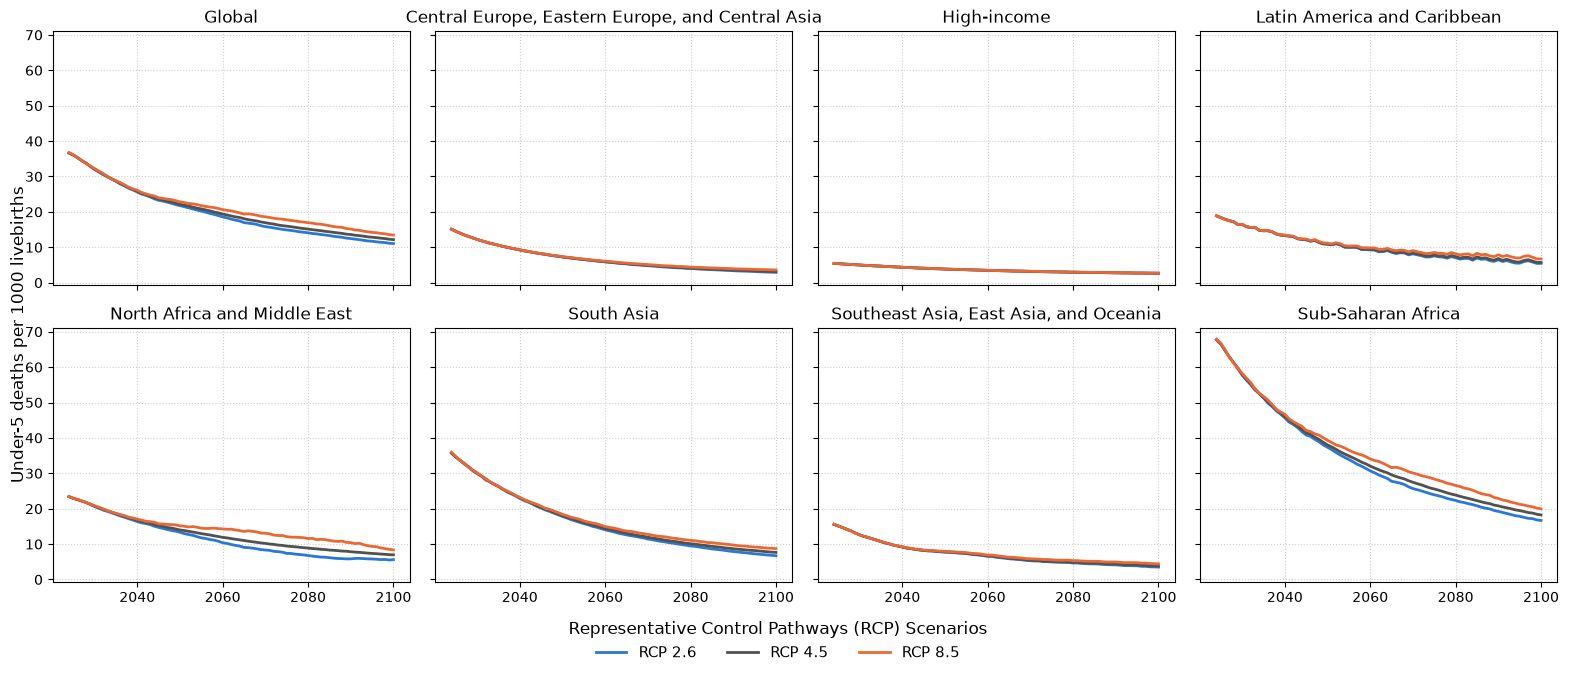

,year_id,location_name,scenario,millions
0,2050,Global,ssp245 - ssp126,3.055073
1,2050,Global,ssp585 - ssp126,6.631760
2,2050,Global,ssp585 - ssp245,3.576687
3,2050,"Central Europe, Eastern Europe, and Central Asia",ssp245 - ssp126,0.003395
4,2050,"Central Europe, Eastern Europe, and Central Asia",ssp585 - ssp126,0.020810
5,2050,"Central Europe, Eastern Europe, and Central Asia",ssp585 - ssp245,0.017415
6,2050,High-income,ssp245 - ssp126,0.000522
7,2050,High-income,ssp585 - ssp126,0.004683
8,2050,High-income,ssp585 - ssp245,0.004161
9,2050,Latin America and Caribbean,ssp245 - ssp126,0.025886


In [53]:
# Child mortality: cumulative scenario differences and line plots ###########
#
# RRA has no directly usable 5q0, so it is rebuilt from the two parts the
# pipeline does model, draw by draw:
#
#     5q0 = 1 - (1 - 28q0) * (1 - 5q28)
#
#   28q0  neonatal_mortality/results/2026_10_08.01  (shifted)
#   5q28  child_mortality/results/2026_10_16.01     (shifted)
#
# Draw by draw and not on the draw means, because the identity is not linear.
# The direct 5q0 run (2026_10_01.01) is properly anchored to GBD but falls
# below 28q0 in 216 locations after 2023, which cannot happen - neonatal
# deaths are a subset of under-5 deaths. The recombination has zero such
# cells, which is why 5q28 was fit separately in the first place.
#
# From there it is the neonatal recipe: take the scenario minus reference
# difference, roll it up the hierarchy with the pipeline's weight (age
# group 1, which expands to ages 2, 3, 388, 389, 238, 34), and add it to the
# FHS under-5 series exactly as published.
u5m_fhs_counts = build_u5m_fhs_counts()
u5m_fhs_table1 = cumulative_difference_table(u5m_fhs_counts)

fig = plot_superregion_rates(u5m_fhs_counts, ylabel=U5M_YLABEL)
fig.savefig(os.path.join(PLOT_OUTPUT, U5M_PLOT_FILE), dpi=200, bbox_inches="tight")
u5m_fhs_table1.to_csv(
    os.path.join(PLOT_OUTPUT, U5M_TABLE_FILE), index=False, encoding="utf-8-sig"
)
plt.show()
u5m_fhs_table1